## Ordinary Differential Equations: Numerical Approximations

#### Pablo Montes, Joaquín Pelle and Oscar Reula

In [1]:
using Plots
using LaTeXStrings

### Formalizing the problem and using Euler's method.

We shall be looking for approximations to the following equation:

\begin{equation}
\frac{dy}{dt} = f(y)
\end{equation}

Notice that we have not assumed an explicit dependence on the free variable $t$ on the function $f$. We shall see later how to incorporate this dependence. This incorporation is very simple while its inclusion from the begining of the discussion only makes the notation more clumsy. We shall further assume $f(\cdot)$ is several times differentiable according to the needs of the methods we shall develop.

The general theory of Ordinary Differential Equations asserts:

Given a value $y_0$ inside the domain of definition of $f(\cdot)$ there will be a finite interval $[0,T]$ and a solution $y(t)$ with $y(0) = y_0$.
We want to find sequences of approximations that converge to $y(t)$.

That is, we want to find a norm and a sequence of approximations so that:
 
$
\{\tilde{w}_i(t)\}
$ 
and,

$$
|| y - \tilde{w}_i|| \to 0 \;\;\; \text{when} \;\; i \to \infty.
$$

In practice we shall not work with the sequence of functions $\tilde{w}_i$,
but rather with sequences of finite vectors $\{w^n_i\}$ such that $\tilde{w}_i$ is an interpolation for those points. That is, $\tilde{w}_i(t_n) = w_i^n$, for some specific set of values $\{t_n\} \subset [0,T], n=1,\dots, N$.

To simplify calculations we shall assume that the set of points $\{t_n\} \subset [0,T]$ are equidistant, that is:

$$
t_n = (n-1)*\Delta t \;\;\;\;\;\;\;\;\;\;\;\;\;\; \Delta t = T/(N-1).
$$

In practice this is not always so, sometimes it pays to adapt the step between consecutive points according to the values $f(\cdot)$ takes along the evolution, so that the error stays within a prescribed tolerance. That is we can *adapt* dynamically to the problem at hand. The generalization is rather straightforward for the methods we are going to develop. 

The simplest approximation is to use Taylor series to first order: Knowing the value of $w^n$ we can use Taylor's to approximate the value at $w^{n+1}$,

$$
y(t_{n+1}) = y(t_n + \Delta t) \approx y(t_n) + \frac{dy}{dt}|_{y(t)=y(t_n)} \Delta t +  \frac{d^2y}{dt^2}(\zeta)\frac{\Delta t^2}{2}  \approx y(t_n) + f(y(t_n)) \Delta t \;\;\;\;\;\;\; \zeta \in [t_n, t_{n+1}]
$$

That gives then the approximation:

$$
w^{n+1} = w^n +  f(w^n) \Delta t. 
$$

Given $w^1 = y_0$ this algorithm gives a unique and finite sequence of points  
$\{w^n\}, n = 1, \dots, N$. From this sequence we later build the interpolation to get $\tilde{w}_N$. 

This method is called *Explicit Euler*.

### Step Error: 

The step error is defined as the approximation error after one step, assuming there was  no error at the previous step. This is obviously a false assumption but is a very good indicator to classify the methods, and then can be used and corrected in order to obtain the total error.  

$$
\begin{array}{ll}
e^n &= y(t_n) - w^n = y(t_{n-1}) +   \frac{dy}{dt}|_{y = y(t_{n-1}) } \Delta t  + \frac{d^2y}{dt^2}|_{t=\zeta} \frac{\Delta t^2}{2} - w^{n-1} - f(w^{n-1}) \Delta t  \\
&= e^{n-1} + [f(y(t_{n-1})) - f(w^{n-1})] \Delta t + \frac{d^2y}{dt^2}|_{t=\zeta} \frac{\Delta t^2}{2}
\end{array}
$$

Where we have used again the mean value theorem for the second derivative.
Assuming that $e^{n-1}=0$, we obtain, 

$$
|e^n| = |y(t_n) - w^n| \leq R \Delta t^2 
$$

where,

$$
R = \max_{t \in [0,T]} \| \frac{1}{2}\frac{d^2y}{dt^2}|_{t}\|
$$

As we are going to increase the error by a quantity of order $\Delta t^2$ at every time step and we are going to take $N = \frac{T}{\Delta t}$ steps, the *global error* will be of order $\Delta t$. That is the global error of Euler's method is first order.

#### Example:

We shall apply Euler's method to the equation:

$$
\frac{dy}{dt} = \lambda y
$$

The exact solution is: $y(t) = y_0 e^{\lambda t}$ 

This equation, the linear equation, is very important because it appears when analyzing stability and error propagation. 

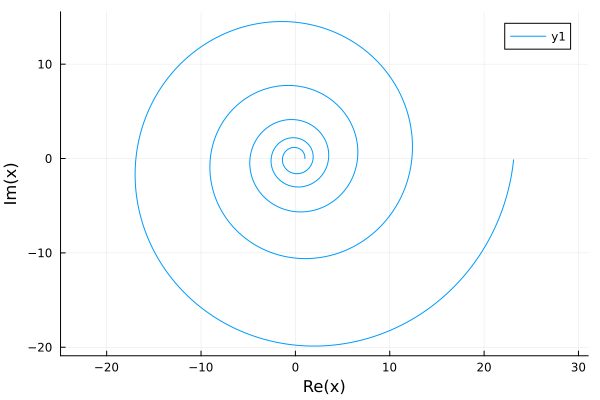

In [2]:
λ = 0.1 + im
xr = 0.0:0.01:10π
plot(exp.(λ*xr), aspectratio=1)

In particular, if we take $\lambda = i$ the solution is bounded by $y_0$ and is given by:

$$
y(t) = y_0 e^{it} = y_0\;(cos(t) + i \; sin(t))
$$

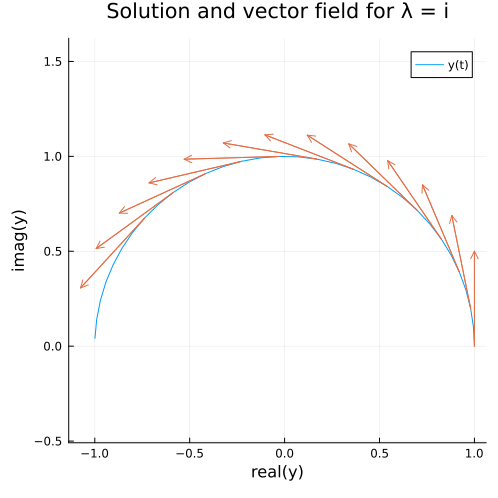

In [3]:
t = 0:0.1:π
xv = cos.(t)
yv = sin.(t)
ts = 0:0.2:(π-0.6)
xs = cos.(ts)
ys = sin.(ts)
dt = 0.5
vx = -dt.*sin.(ts)
vy = dt.*cos.(ts);
plt = plot(xv,yv,size=(500,500), aspectratio=1, title="Solution and vector field for λ = i", label="y(t)",xlabel="real(y)", ylabel="imag(y)")
quiver!(plt,xs,ys,quiver=(vx,vy), label="λ*y(t) at y(t)")
current()
#png(plt, "vector_field")


Euler's algorithm gives the following sequence: 

$$
w^{n+1} = w^{n} + \lambda w^n \Delta t = (1 + \lambda  \Delta t) w^n
$$

whose solution is:

$$
w^n = (1 + \lambda  \Delta t)^{(n-1)} w^1,
$$

with local error: $\frac{|\lambda \Delta t|^2}{2} \max_{t \in [0,T]}||e^{\lambda t}||$. 

We see from the plot below that even with $\lambda = i$, and therefore with $|e^{\lambda t}| = 1$ the error is very big.

In fact, for  $\lambda = i$,  

$$|1 + \lambda \Delta t| = \sqrt{(1+i \Delta t)(1-i \Delta t)} = \sqrt{1 + \Delta t^2} > 1.
$$

And therefore there is an amplification of the approximation with time which it is not present in the exact solution for all $\Delta t >0$. 

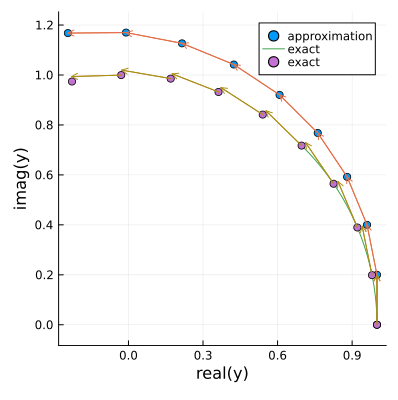

In [4]:
ts = 0:0.01:π/3.8
xs = cos.(ts)
ys = sin.(ts)

dt = 0.2
N = 10
xvv = zeros(N)
yvv = zeros(N)
vx = zeros(N)
vy = zeros(N)
xvv[1] = 1.0
yvv[1] = 0.0

for i in 2:N
    vx[i-1] = -dt*yvv[i-1]
    vy[i-1] = dt*xvv[i-1]
    xvv[i] = xvv[i-1] + vx[i-1]
    yvv[i] = yvv[i-1] + vy[i-1]
end
vx[end] = 0.0 #-dt*y[end]
vy[end] = 0.0 #dt*x[end]

plt = scatter(xvv,yvv,size=(400,400),label="approximation",xlabel="real(y)", ylabel="imag(y)", aspectratio=1)
quiver!(plt,xvv,yvv,quiver=(vx,vy))

xe = [cos(dt*(i-1)) for i in 1:N]
ye = [sin(dt*(i-1)) for i in 1:N]
plot!(plt,xs,ys,label="exact")
scatter!(plt,xe,ye,label="exact")
quiver!(plt,xe[1:end-1],ye[1:end-1],quiver=(-dt*ye[1:end-1],dt*xe[1:end-1]))
current()
#png(plt, "vectorfieldEuler")

## Higher order methods:

Clearly Euler's method is not appropriate for many problems, for instance, to compute planetary orbits or the evolution of hyperbolic equations. We shall look now at other methods which have error which behaves as higher order in $\Delta t$
and which do not suffer from such a big amplification. 

We shall say that a method is *order p* if its *local error* scales as $\Delta t^{p+1}$, so that its *global error* scales as $\Delta t^p$ ($p \geq 1$).

### 1. Taylor expansions

One way of obtaining better approximations is to directly continue with Taylor expansions to higher orders:

$$
\begin{array}{ll}
y(t_{n+1}) &= y(t_n + \Delta t)  \\
&= y(t_n) + \frac{dy}{dt}|_{t=t_{n}} \Delta t  + \frac{d^2y}{dt^2}|_{t=t_n} \frac{\Delta t^2}{2}  + \frac{d^3y}{dt^3}|_{t=\zeta} \frac{\Delta t^3}{3!}  \\
&= y(t_n) + f(y(t_{n})) \Delta t  + \frac{df(y)}{dt}|_{t=t_n} \frac{\Delta t^2}{2}  + \frac{d^2f(y)}{dt^2}|_{t=\zeta} \frac{\Delta t^3}{3!}  
\end{array}
$$

Using now that: 
$$\frac{df(y)}{dt} = \frac{df}{dy}\frac{dy}{dt} =  \frac{df}{dy}f
$$  
$$
\frac{d^2f(y)}{dt^2} = \frac{d^2f}{dy^2} f^2 + (\frac{df}{dy})^2f,
$$
we obtain:

$$
\begin{array}{ll}
y(t_{n+1}) &= y(t_n) + f(y(t_{n})) \Delta t  + \frac{df}{dy}(y)f(y)|_{t=t_n} \frac{\Delta t^2}{2}  + [\frac{d^2f}{dy^2}(y) f^2(y) + (\frac{df}{dy})^2(y)f(y)]|_{t=\zeta} \frac{\Delta t^3}{3!} %\nonumber 
\end{array}
$$

That suggest we use the approximation of $y(t_{n+1})$ given by,

$$
w^{n+1} = w^n + f(w^n) \Delta t  + \frac{df}{dy}(w^n)f(w^n) \frac{\Delta t^2}{2}   
$$

with local error, 

$$
\max_{t \in [0,T]}\|[\frac{d^2f}{dy^2}(y) f^2(y) + (\frac{df}{dy})^2(y)f(y)]|_{t} \| \frac{\Delta t^3}{3!}
$$

These set of methods could be very good if one can obtain and evaluate the higher-order derivatives efficiently. That depends on how complicated is the expression for $f$ and its derivatives. With symbolic manipulation libraries one can compute such expressions very efficiently, so it can be doable in many cases.
For these methods, obtaining higher order methods only requires to compute and evaluate further derivatives.

#### Example: 

Taking the previous example:

$$
\frac{dy}{dt} = \lambda y
$$

we obtain to second order the following algorithm:


$$
w^{n+1} = w^{n} + \lambda w^n \Delta t  + \lambda^2 w^n \frac{\Delta t ^2}{2} = (1 + \lambda  \Delta t +  \frac{1}{2}(\lambda  \Delta t)^2) w^n
$$

That has as a solution: 

$$
w^n = (1 + \lambda  \Delta t + \frac{1}{2}(\lambda  \Delta t)^2)^{(n-1)} w^1
$$

For the case $\lambda = i$ we find a smaller but non-zero amplification:

$$
|1 + \lambda  \Delta t + \frac{1}{2}(\lambda  \Delta t)^2| = \sqrt{1 + \frac{\Delta t^4}{4}}.
$$ 
 
 

### 2. Multistep methods:

These methods use values of the $y$ and $f(y)$ at multiple steps. 

Using again Taylor's expansion we get,

$$
 y(t_{n+1}) = y(t_n + \Delta t)  
= y(t_n) + \frac{dy}{dt}|_{t=t_{n}} \Delta t  + \frac{d^2y}{dt^2}|_{t=t_n} \frac{\Delta t^2}{2}  
+ \frac{d^3y}{dt^3}|_{t=t_n} \frac{\Delta t^3}{3!}  + \frac{d^4y}{dt^4}|_{t=\zeta} \frac{\Delta t^4}{4!} 
$$

taking  $\Delta t \to -\Delta t$ and subtracting we see that we can eliminate the second-order term, 

$$
 y(t_n + \Delta t)  -  y(t_n - \Delta t)
= 2\frac{dy}{dt}|_{t=t_{n}} \Delta t    
+ \frac{d^3y}{dt^3}|_{t=\zeta} \frac{\Delta t^3}{3}  
$$

Therefore the algorithm : 

$$
w^{n+1} = w^{n-1} + 2\Delta t f(w^n)
$$

has a local error of third order!

This type of schemes has the advantage of being of higher order with the same number of evaluations of $f$ as Euler's method. With one evaluation we get one order more! On the other hand we need to store two previous values, that is, $w^n$ and $w^{n-1}$. The problem of these methods is that they can develop spurious solutions leading to instabilities. That makes them impractical.

#### Example: 

Using the linear equation:

$$
\frac{dy}{dt} = \lambda y,
$$

the algorithm becomes: 

$$
w^{n+1} = w^{n-1} + 2 \mu w^n \;\;\;\;\;\;\; \mu := \lambda \Delta t.
$$

The solutions are: 

$$
w^n = A^+ S^n_+  + A^- S^n_-  \;\;\;\;\;\; S_{\pm} = \mu \pm \sqrt{\mu^2 + 1}
$$

The constant, $(A_+, A_-)$, are obtained from the initial data via the values of $(w^1,w^2)$. For instance, to obtain $w^1$ we use the initial data, and for the values of $w^2$ we use Euler's method with $w^1$ as initial data. 

Note that:
$$
S_+ \;S_- = -1, \;\;\;\; \text{and therefore} \;\;\;\; |S_+| \;|S_-| = 1
$$

Thus, except in the special cases where, 

$$
S_{+} = e^{i \theta}, \;\;\;\; S_{-} = -e^{-i \theta}
$$ 
one of the $S$ will have absolute value bigger than $1$ and so that mode will grow in time, even in cases where the exact solution decays (for instance $\lambda = -1$). 

#### Exercise: 

Verify the roots computation by substituting in the expression the solutions given. Evaluate for different values of $\mu = \lambda\Delta t$, e.g. on the imaginary axis and on the negative real axis. 
 

### 3. One step methods:

In multiple steps methods we could have a smaller local error by evaluating $f$ at intermediate points. Unfortunately these methods in general produce spurious solutions which in time can dominate the approximation taking it very far away from the real solution. Even in cases where we know the exact solution is bounded or decreasing.

Instead of taking two previous times we could take a first step up to an intermediate time, that is to multiply $f$ by  $\frac{\Delta t}{2}$, 
to reach to $w^* = w^n + \frac{\Delta t}{2}f(w^n)$. 
At this mid-point we could compute $f(w^*)$ and with this value advance a full step. The scheme becomes: 

$$
\begin{array}{ll}
k_1 &= \Delta t f(w^n)  \\
k_2 &= \Delta t f(w^n + \frac{1}{2}k_1)  \\
w^{n+1} &= w^{n} + k_2  
\end{array}
$$

This scheme is called *Mid-Point* or *Improved Euler*. This method is second order (local error $\mathcal{O}(\Delta t^3)$) with two $f$ evaluations and behaves much better for orbits as we shall see in the standard example:

#### Example:

$$
\frac{dy}{dt} = \lambda y.
$$

Using the Mid-Point algorithm we have (with $\mu = \Delta t * \lambda$):

$$
\begin{array}{ll}
k_1 &= \mu w^n  \\
k_2 & = \mu (w^n + \frac{1}{2}k_1) \\
w^{n+1} &= w^{n} + \mu(w^n + \frac{1}{2} k_1)  = (1 + \mu + \frac{\mu^2}{2})w^n  
\end{array}
$$

This is identical (for this particular equation) to the algorithm we found for Taylor's expansions. 
So we know that it amplifies, even for $\lambda$ imaginary, but at a smaller rate than Euler's.
 
 

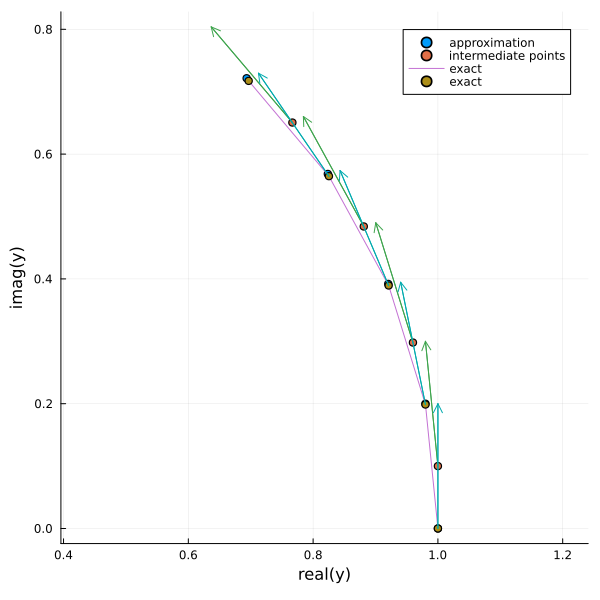

In [5]:
dt = 0.2
N = 5
x = zeros(N)
xint = zeros(N-1)
y = zeros(N)
yint = zeros(N-1)
vx = zeros(N)
vy = zeros(N)
x[1] = 1.0
y[1] = 0.0
for i in 2:N
    vx[i-1] = -dt*y[i-1]
    vy[i-1] = dt*x[i-1]
    xint[i-1] = x[i-1] + vx[i-1]/2
    yint[i-1] = y[i-1] + vy[i-1]/2
    vx[i-1] = -dt*yint[i-1]
    vy[i-1] = dt*xint[i-1]
    x[i] = x[i-1] + vx[i-1]
    y[i] = y[i-1] + vy[i-1]
end
vx[end] = 0.0 #-dt*y[end]
vy[end] = 0.0 #dt*x[end]

plt = scatter(x,y,size=(600,600),
    #xaxis=(0.6,1.01),
    label="approximation", ms=4)
scatter!(plt,xint,yint,label="intermediate points", ms=4)
quiver!(plt,xint,yint,quiver=(vx[1:end-1],vy[1:end-1]))

xe = [cos(dt*(i-1)) for i in 1:N]
ye = [sin(dt*(i-1)) for i in 1:N]
plot!(plt,xe,ye,label="exact",xlabel="real(y)", ylabel="imag(y)", aspectratio=1)
scatter!(plt,xe,ye,label="exact", ms=4)
quiver!(plt,xe[1:end-1],ye[1:end-1],quiver=(-dt*ye[1:end-1],dt*xe[1:end-1]))
current()
#png(plt, "vectorfieldMidPoint")

Alternatively we could have evolved a complete step, that is with $\Delta t$,  to obtain a point $w^* = w^n + \Delta t f(w^n)$. At this approximate point we could have computed $f(w^*)$, to finally advance a full step from $w^n$ but using the averaged value for $f$. In this case the scheme results:
$$
\begin{array}{ll}
k_1 &= \Delta t f(w^n) %\nonumber 
\\
k_2 &= \Delta t f(w^n + k_1) %\nonumber 
\\
w^{n+1} &= w^{n} + \frac{1}{2}(k_1 + k_2) 
%\nonumber 
\end{array}
$$

This algorithm is called  *Heun's method*. Both methods have local errors of order $\Delta t^3$.

Actually these two methods are not the only ones which are third order in local error. There is a one parameter family of them using just two $f$-evaluations. Next we describe them and in doing so find a useful expression to bound the error. 
To find them we start with a generic method using two $f$-evaluations: 

$$
\begin{array}{ll}
k_1 &= \Delta t f(w^n) %\nonumber 
\\
k_2 &= \Delta t f(w^n + \alpha_{21} k_1) %\nonumber 
\\
w^{n+1} &= w^{n} + (A_1 k_1 + A_2 k_2) %\nonumber 
\end{array}
$$

The Mid-Point method corresponds to the election: $\alpha_{21} = \frac{1}{2}$, $(A_1 = 0, A_2 = 1)$, Heun's method to the following: $\alpha_{21} = 1$, $(A_1 = \frac{1}{2}, A_2 = \frac{1}{2})$.

We apply Taylor's expansion to the exact solution:

$$
\begin{array}{ll}
y(t_{n+1}) &= y(t_n) + f(y(t_{n})) \Delta t  + \frac{df}{dy}(y)f(y)|_{t=t_n} \frac{\Delta t^2}{2}  + [\frac{d^2f}{dy^2}(y) f^2(y) + (\frac{df}{dy})^2(y)f(y)]|_{t=\zeta} \frac{\Delta t^3}{3!}, %\nonumber 
\end{array}
$$

on the other hand we have,

$$
\begin{array}{ll}
w^{n+1} &= w^n + (A_1 k_1 + A_2 k_2) %\nonumber 
\\
&= w^n + A_1 \Delta t f(w^n) + A_2 \Delta t f(w^n + \alpha_{21} k_1 ) %\nonumber 
\\
&= w^n + \Delta t (A_1 f(w^n) + A_2 [f(w^n) + \frac{df}{dy}(w^n)\alpha_{21}\Delta t f(w^n)] )+ O(\Delta t^3)  %\nonumber 
\\
&= w^n + \Delta t  (A_1 + A_2) f(w^n) + A_2\alpha_{21} \frac{df}{dy}(w^n) f(w^n)\Delta t^2 + O(\Delta t^3)  %\nonumber
\end{array}
$$

Comparing both expressions we see that to have an error of order $O(\Delta t^3)$ we need:

$$
A_1 + A_2 = 1 \;\;\;\;\; A_2 \alpha_{21} = \frac{1}{2}.
$$

These conditions give a one parameter family of second-order methods (local error $\mathcal{O}(\Delta t^3)$) (two conditions for three unknowns).


These one-step methods are known with the generic name of *Runge Kutta methods*, they are very efficient and easy to implement since we only need to compute $f$ at some specific points and can be implemented to very high precision. 

Among them there is one that it is widely used, the fourth-order **RK4**: 

```
function RK4(f,w0,t0,h,p)
    k1 = h*f(w0,p)
    k2 = h*f(w0 + k1/2,p)
    k3 = h*f(w0 + k2/2,p)
    k4 = h*f(w0 + k3,p)   
    return w0 + (k1 + 2k2 + 2k3 + k4)/6
end
```


#### Exercise:

Apply this method to the linear equation and write down the resulting algorithm, that is,

$$
w^{n} = A^n w_0
$$

Check that when $\lambda = i$ one can choose ranges of values for $\Delta t$ such that $|A| \leq 1$.

## Practice:

In practice there are many diverse methods that can be used. Which to use depends on several issues: how costly it is to compute $f$ or its derivatives, whether we are solving a conservative system (orbits) and want to preserve some constants of importance or dissipative systems or whether $f$ is very big in some directions, that is if the problem is *stiff*, etc. Also whether the system has big or small dimensions (number of variables).

There are hundreds of different methods, for instance in this library there is a list with a large number of them whose schemes have been implemented [https://diffeq.sciml.ai/stable/solvers/ode_solve/](https://diffeq.sciml.ai/stable/solvers/ode_solve/)

If the characteristics of the system are  not known in advance it is convenient to start with a well-known one, like **RK4**.

It is also usual to use embedded algorithms, these are Runge-Kutta methods that at the same time (with the same total number of evaluations) compute approximations of different orders, say of $4^{th}$ and $5^{th}$ order. This allows to know with high precision the local error of the coarser method and so to adjust the time step to keep it bounded according to the required error tolerances.

## Systems

So far we have concentrated in the simplest systems, that is those with a unique variable and so the function $f$ taking reals to reals or complex to complex numbers. 

In practice the systems to be solved are rather more complex and we look now to deal with them with the methods already introduced.

#### Example:

Suppose we want to solve the equation describing the motion of a mass hanging from a spring. 

The force that the spring exerts over the mass is given by Hooke's law, that is $F(x) = -kx$, where the displacement is counted from the equilibrium position obtained when the gravity force (assumed constant) is canceled by the spring force. The constant $k$ is called Hooke's constant and depends only on the spring's composition and form. 

If we displace the mass a distance $x_0$ and release it there will be a restoring force in the opposite direction,  $F(x) = -kx$ which will generate an acceleration on the mass according to Newton's laws. Thus, we have the equation: 

$$
m\frac{d^2x}{dt^2} = -kx
$$
The solution to this equation is to find a function $x(t)$ that when substituted in the equations satisfies it and that at  $t=0$,

$$
x(0) = x_0 \;\;\;\;\;\;\;\;\;\;\;\; \frac{dx}{dt}|_{t=0} = 0 \;\; \text{(at rest when released)}
$$

But this equation is not of the form we have previously, it has second derivatives with respect to $t$!

To use the methods studied we have to transform it into a *system of equations* of first order in derivatives. We do that by introducing the velocity as another variable:

$$
\begin{array}{l}
\frac{dx}{dt} &= v \\
\frac{dv}{dt} &= -\frac{k}{m}x
\end{array}
$$

Notice that if we obtain a solution to this problem  $(x(t), v(t))$ then,

$$
m\frac{d^2x}{dt^2} = m\frac{dv}{dt} = -kx.
$$

That is $x(t)$ also satisfies the initial equation. We have transformed our second order differential equation into a first order system of differential equations. 

Writing,

$$
\vec{y} = (y_1, y_2) = (x,v) \;\;\;\;\;\; \text{and} \;\;\;\; \vec{f}(\vec{y}) = (v,-\frac{k}{m}x) = (y_2, -\frac{k}{m}y_1)
$$

we obtain:

$$
\frac{d\vec{y}}{dt} = \vec{f}(\vec{y}),
$$ 
but where now the variables are a vector.

#### Exercise: 
Check that $x(t) = x_0 \cos(\omega t)$, $\omega = \sqrt{\frac{k}{m}}$ is the solution sought. Write the vector  $\vec{y}$ for this solution. 




### Geometrical Interpretation:

Let us plot the vector $\vec{f}(y)$ and a solution with $y_0=1$, $\omega = \sqrt{\frac{k}{m}} = 1.4$

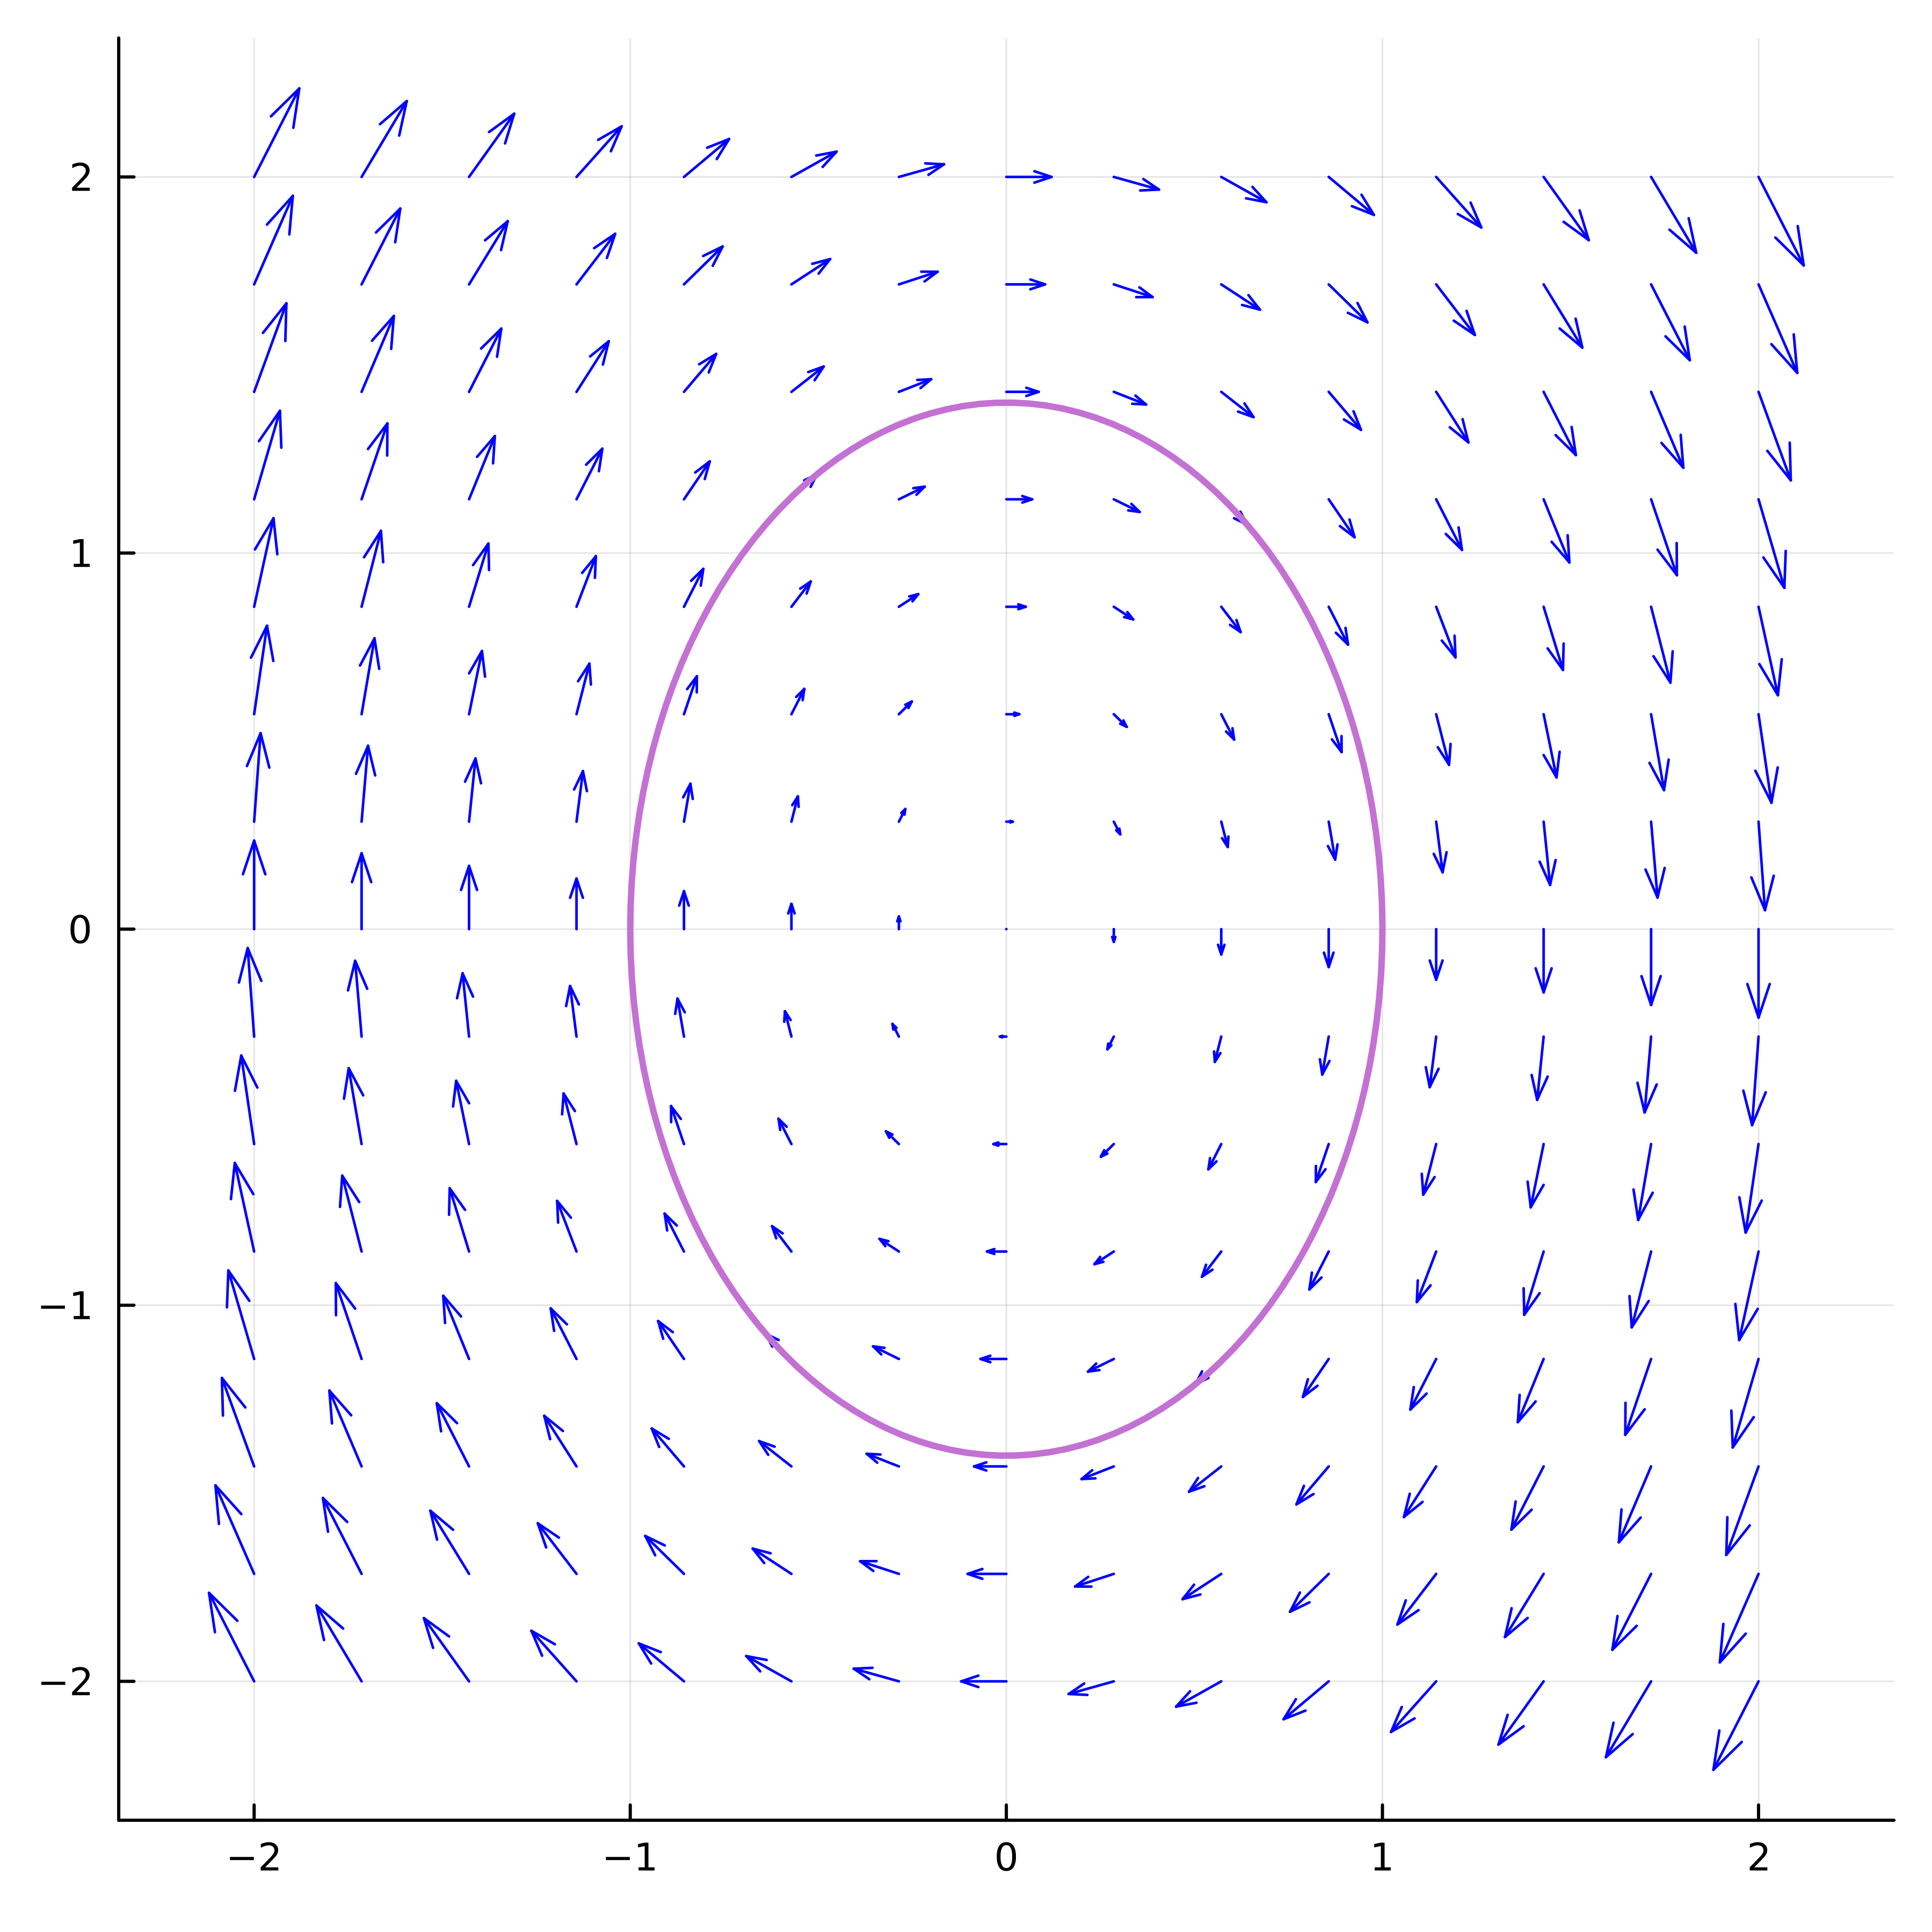

In [6]:
ω = 1.40
scale = 0.2
u_(x, y) = scale * y
v_(x, y) = -ω^2 * scale * x

lims = (-2.2, 2.2)
xs = ys = range(lims...; length=200)
c = 0.3
x = y = range(-2.0, 2.0; length=15)
X, Y = reim(complex.(x', y))        # meshgrid
U, V = c*u_.(x', y), c*v_.(x', y)

gr(legend=false, dpi=600)

# as: arrow head size 0-1 (fraction of arrow length;  la: arrow alpha transparency 0-1
function arrow0!(x, y, u, v; as=0.07, lw=1, lc=:black, la=1)
    nuv = sqrt(u^2 + v^2)
    v1, v2 = [u;v] / nuv,  [-v;u] / nuv
    v4 = (3*v1 + v2)/3.1623  # sqrt(10) to get unit vector
    v5 = v4 - 2*(v4'*v2)*v2
    v4, v5 = as*nuv*v4, as*nuv*v5
    plot!([x,x+u], [y,y+v], lw=lw, lc=lc, la=la)
    plot!([x+u,x+u-v5[1]], [y+v,y+v-v5[2]], lw=lw, lc=lc, la=la)
    plot!([x+u,x+u-v4[1]], [y+v,y+v-v4[2]], lw=lw, lc=lc, la=la)
end

# Alternative to: quiver!(vec(X-U/2), vec(Y-V/2); quiver=(vec(U), vec(V)), color=:red)
# Plot points and arrows with 30% head sizes
plot(label=false, aspectratio=1,size=(600,600))
arrow0!.(X, Y, U, V; as=0.4, lw=0.8,lc=:blue, la=1);
y1e(t) = cos(ω*t)
y2e(t) = -ω * sin(ω*t)
plot!(y1e,y2e , 0, 2π, lw=2, label="y(t)")
Plots.current()

**We see that solutions are orbits whose tangent vector is just $\vec{f}$!**

*The solutions are curves whose tangent vector (velocity vector) at any point along them is $\vec{f}(y(t))$.*

If $\vec{f}$ is differentiable in a neighborhood $U_p$ of a point $p$, then for any $\vec{y}_0 \in U_p$ there exist a finite interval $[0,T]$ and a curve $y(t):[0,T] \to U_p$ such that:

$$
\frac{d\vec{y}}{dt} = \vec{f}(\vec{y}(t)) \;\;\;\; \text{and} \;\; y(0) = y_0
$$

## Non-autonomous systems

Assume we have now a system where the vector field $\vec{f}$ not only depends on $\vec{y}$, but also on the free variable $t$.


$$
\frac{d\vec{y}}{dt}(t) = \vec{f}(\vec{y},t) 
$$

For finding a solution to this system it is not enough to give the initial position, but also the initial time, $t_0$. Different initial times give different solutions. Thus the initial condition is now $\vec{y}(t_0)=y_0$.

We shall see now how to convert this system into an autonomous system with one more variable so that we can apply all the above methods to it. 

Consider the following system:

$$
\begin{array}{l}
\frac{d\vec{y}}{dt} &= \vec{f}(\vec{y},\lambda) \\
\frac{d\lambda}{dt} &= 1
\end{array}
$$

**Assertion:** this autonomous system is equivalent to the previous one if we give as initial condition $(\vec{y}(t_0)=\vec{y}_0,\ \lambda(t_0) = t_0)$

Indeed, assume we have a solution to this second system, that is a pair $(\vec{y}(t), \lambda(t))$.
Since the solution to the $\lambda$ equation is $\lambda(t) = t$ $t \in [t_0,T]$, we can substitute those values in the equation for $\vec{y}(t)$ and so see that it satisfies: 

$$
\frac{d\vec{y}}{dt}(t) = \vec{f}(\vec{y},\lambda) = \vec{f}(\vec{y},t)
$$

Thus, by enlarging our system in one extra variable ($\lambda$), that is taking as a system,

$$
\frac{d}{dt}\left(
    \begin{array}{l}
    \vec{y}\\
    \lambda
    \end{array}
    \right)
    = 
    \left(
    \begin{array}{l}
    \vec{f}(y,\lambda)\\
    1
    \end{array}
    \right)
$$
we can treat the system as autonomous.

#### Exercise:

If we use the technique of enlarging the system to include non-autonomous systems we can deduce the formulae for non-autonomous systems. For instance, for Heun's method we would have:
$$
\begin{array}{ll}
k_1 &= \Delta t * f(w^n, \lambda^n)  \\
k_1{}_{\lambda} &= \Delta t * 1  \\
k_2 &= \Delta t * f(w^n + k_1, \lambda^n + k_1{}_{\lambda} ) = \Delta t f(w^n + k_1, \lambda^n + \Delta t)  \\
k_2{}_{\lambda} &= \Delta t * 1 \\
w^{n+1} &= w^{n} + \frac{1}{2}(k_1 + k_2) %\nonumber 
\\
\lambda^{n+1} &= \lambda^n + \frac{1}{2}(k_1{}_{\lambda} + k_2{}_{\lambda}) =  \lambda^n + \Delta t
\end{array}
$$

that is,

$$
\begin{array}{ll}
k_1 &= \Delta t * f(w^n, t^n)  \\
k_2 &= \Delta t f(w^n + k_1, t^n + \Delta t)  \\
w^{n+1} &= w^{n} + \frac{1}{2}(k_1 + k_2) %\nonumber 
\\
t^{n+1} &= t^n + \Delta t
\end{array}
$$

Check that for RK4 we should obtain: ($h=\Delta t$)

```
function RK4(f,w0,t0,h,p)
    k1 = h*f(w0,t0,p)
    k2 = h*f(w0 + k1/2,t0 + h/2,p)
    k3 = h*f(w0 + k2/2,t0 + h/2,p)
    k4 = h*f(w0 + k3,t0 + h,p)   
    return w0 + (k1 + 2k2 + 2k3 + k4)/6
end
```

## One Step Methods: Error Propagation

We are trying to approximate the solutions to the equation system,

\begin{equation}
\dot{u} = f(u)
\end{equation}

where $u = u(t)$, is a curve in $\mathbb{R}^n$, and $f(u)$ is a vector field in some open set $U$ of $R^n$. 
In case of an equation system for which $f=f(u,t)$, we simply define $\tilde{u} = (u,t)$ and $\tilde{f} = (f,1)$. That is, we extend the system by one equation. The initial conditions at $t=t_0$ are also extended to $\tilde{u}_0 = (u_0,t_0)$. 

One-step methods are those where the values of the approximation at a time $t+\Delta t$ are obtained from the values of the approximation at $t$. No further information from previous values is used. That is we have an algorithm of the form:

\begin{equation}
v^{n+1} = v^{n} + \Delta t A_p(v^n,\Delta t)
\end{equation}

Where $A_p$ is the algorithm. The index $p$ characterizes the order of the truncation error of the method. 
For instance for Euler's method,

\begin{equation}
Euler_1(v^n,\Delta t) = f(v^n)
\end{equation}

For the mid-point rule, 

\begin{equation}
MidPoint_2(v^n, \Delta t) = f(v^n + \frac{\Delta t}{2}f(v^n))
\end{equation}

For Heun's method, 

\begin{equation}
Heun_2(v^n, \Delta t) = \frac{1}{2}[f(v^n) + f(v^n + \Delta t f(v^n))]
\end{equation}

All explicit Runge Kutta algorithms, as well as the Taylor ones, are of this type. 

### Truncation error

The truncation error is the error for which the algorithm approximates the equation when applied to a smooth solution,
in other contexts is called the **residual**.

\begin{equation}
e_T := \frac{u^{n+1} - u^n}{\Delta t} - A_p(u^n, \Delta t).
\end{equation}


We can compute it expanding all terms in Taylor series. 
Notice that this in particular implies smoothness of $u$ and $f$. 
In the notation that follows $u^n = u(t_n)$, where $t_n$ is the time at step $n$. For uniform time-steps $t_n = n*\Delta t$.

The first term is general, 

\begin{equation}
\frac{u^{n+1} - u^n}{\Delta t} = \dot{u}^n + \ddot{u}^n \frac{\Delta t}{2} + \dddot{u}^n \frac{\Delta t^2}{6} + \mathcal{O}(\Delta t^3)
\end{equation}
To it we can apply the equation, and use the chain rule. For instance, $\dot{u} = f(u)$,  $\ddot{u} = \dot{f}(u) = f_u \dot{u} = f_u f$. This way we get rid of all time derivatives, resulting in an expression that only depends on $u$ at time $t_n$.

\begin{equation}
\frac{u^{n+1} - u^n}{\Delta t} = f(u^n) + f_u(u^n) f(u^n) \frac{\Delta t}{2} + [f_{uu}(u^n)f^2(u^n) + f_u^2(u^n) f(u^n)]  \frac{\Delta t^2}{6} + \mathcal{O}(\Delta t^3)
\end{equation}

The second term depends on the algorithm. For instance, for the Euler method, and keeping  only the first two terms above we get, 
\begin{align*}
e_T &= \frac{u^{n+1} - u^n}{\Delta t} - f(u^n) \\
       &= f(u^n) + f_u(u^n) f(u^n) \frac{\Delta t}{2}  - f(u^n) \\
       &=  f_u(u^n) f(u^n) \frac{\Delta t}{2} + \mathcal{O}(\Delta t^2)
\end{align*}
%
So, for a generic smooth $f(u)$ the local truncation error is first order ($p=1$). 


It is clear from the construction that the truncation error is a function of the solution and its derivatives at the given time, or, once the derivatives have been substituted using the equation, just a function of $u$ at that time. We have an expression for the truncation error (or residual) in terms of $f$ and its derivatives evaluated at the solutions. 
Thus, in many cases if we know $f$ in a region, we can estimate that truncation error on a whole region. 

For the mid-point method we get:

\begin{align*}
e_T &= \frac{u^{n+1} - u^n}{\Delta t} - f(u^n + \frac{\Delta t}{2}f(u^n)) \\
       &=  f(u^n) + f_u(u^n) f(u^n) \frac{\Delta t}{2} + [f_{uu}(u^n)f^2(u^n) + f_u^2(u^n) f(u^n)]  \frac{\Delta t^2}{6} \\
       &- [f(u^n) + f_u(u^n)  \frac{\Delta t}{2}f(u^n) + f_{uu}(u^n)  \frac{\Delta t^2}{8}f(u^n)^2]         + \mathcal{O}(\Delta t^3) \\
       &= [f_{uu}(u^n)  \frac{1}{24}f(u^n)^2 +  f_{u}^2(u^n)  \frac{1}{6}f(u^n)]\Delta t^2 + \mathcal{O}(\Delta t^3)
\end{align*}

Thus, we see that the **truncation error is order 2**. 

**Exercise:** Find all methods of second order of the form:
\begin{align*}
q_1 &= f(v^n) \\
q_2 &= f(v^n + \Delta t \alpha_{21} q_1) \\
RK_2(v^n, \Delta t) &= (A_1 q_1 + A_2q_2).
\end{align*}
Hint: imposing second order should give the conditions: $A_1+A_2=1$, and $A_2\alpha_{21}= \frac{1}{2}$. 


**Exercise:** Compute the truncation error for Runge Kuta of order four,
\begin{align*}
q_1 &= f(v^n) \\
q_2 &= f(v^n + \frac{\Delta t}{2}q_1) \\
q_3 &= f(v^n + \frac{\Delta t}{2}q_2) \\
q_4 &= f(v^n + \Delta t q_3) \\
RK_4(v^n, \Delta t) &= \frac{1}{6}(q_1 + 2q_2 + 2q_3 + q_4).
\end{align*}

**Exercise:** For a function $f(u,t)$ the generic RK method is of the form:

\begin{align*}
q_1 &= f(v^n, t_n) \\
q_2 &= f(v^n + \Delta t\,\alpha_{21} q_1, t_n + \beta_2\Delta t) \\
q_3 &= f(v^n + \Delta t(\alpha_{31} q_1 + \alpha_{32} q_2), t_n + \beta_3\Delta t) \\
\cdots & \cdots \\ 
q_s &= f(v^n + \Delta t(\alpha_{s1} q_1 + \cdots + \alpha_{s(s-1)} q_{s-1}), t_n + \beta_s\Delta t) \\
\text{RK}_s(v^n, \Delta t) &= (A_1 q_1 + A_2 q_2 + \cdots + A_sq_s).
\end{align*}

 Find the values for the $\beta$'s by considering the same expression for an autonomous system  $\dot{\tilde{u} }= \tilde{f}(\tilde{u})$.


### Error Propagation

So far we have computed the truncation error or residual of the algorithm. We now relate it to the actual error and its propagation along the calculation. We shall ignore rounding errors and asume a machine of infinite precision. 
It is important to see how the error propagates for this implies that one can check convergence easily and even improve on the solution. We assume we are given a method with truncation error of order $p$, and define the error as:

\begin{equation}
e^n := \frac{(u^n - v^n)}{\Delta t^p}, \;\;\;\;\; \text{that is, } \;\;\;\; u^n = v^n + \Delta t^p e^n,
\end{equation}
where $u^n:= u(t_n)$ is the exact solution, and $v^0 = u(t_0)$ (same initial data). 

From the truncation error order assumption we have, 
\begin{equation}
u^{n+1} - u^{n} - \Delta t A_p(u^n,\Delta t) = R(u(t_{n}))\Delta t^{p+1} + \mathcal{O}(\Delta t^{p+2}).
\end{equation}

Where from the expansion we know the remainder term is a function only of $u(t)$.

On the other hand the algorithm gives, 

\begin{equation}
v^{n+1} - v^{n} - \Delta t A_p(v^n,\Delta t) = 0.
\end{equation}

Thus, substracting, we  have, 

\begin{equation}
e^{n+1} = e^n + \Delta t [\frac{A_p(u^n, \Delta t) - A_p(v^n,\Delta t)}{\Delta t^p} + R(u(t_{n}))] + \mathcal{O}(\Delta t^2)
\end{equation}

Since $u^n = v^n + \Delta t^p e^n$ we can use Taylor to get, 

\begin{align*}
e^{n+1} &= e^n + \Delta t \frac{(\partial_u A_p(u^n, \Delta t) e^n \Delta t^p)}{\Delta t^p} + \Delta tR(u(t_{n})) +  \mathcal{O}(\Delta t^2) \\
&= e^n + \Delta t [\partial_u A_p(u^n, \Delta t) e^n + R(u(t_{n}))] + \mathcal{O}(\Delta t^2) 
\end{align*}

Since $A_p(u^n, \Delta t)$ depends smoothly on $\Delta t$, to that order we can approximate it by $A_p(u^n,0)$.
Thus, we see that the error satisfies, 

\begin{equation}
e^{n+1} = e^n + \Delta t [\partial_u A_p(u(t_n), 0) e^n + R(u(t_n))] + \mathcal{O}(\Delta t^2) ,
\end{equation}
And we can interpret the sequence $e^n$ as a first order (Euler) approximation to the equation:

\begin{equation}
\dot{\phi}_p = \partial_u A_p(u(t), 0)\phi_p + R(u(t)), \text{error perturbation equation}
\end{equation}
Where the last term is just a source term. 
Notice that this equation does not depend on $\Delta t$! 
Furthermore, $\partial_u A_p(u(t), 0) = \partial_u f(u(t))$.

Therefore we have the following result:

**Assertion:** *Given $f(u)$ smooth, and $u_0$, there exists a time interval $[0,T]$ for which the solution exists and the approximation to it, given by a scheme of order $p$ has the form,*

\begin{equation}
u(t_n) = v^n + \Delta t^p \phi_p(t_n) + \mathcal{O}(\Delta t^{p+1}).
\end{equation}

With $\phi_p(t)$ a solution to the above error perturbation equation. Notice that initially the initial data for the error is zero, but the truncation term $R$ acts as a source and drives it away from zero. 

For example, if we take $f(u) = \lambda u$, then the homogeneous part of the equation for $\phi_1$ is the same as the original equation, so if $Real(\lambda) $ is positive the error, as well as the solution would grow exponentially. So the error can be substantial, even for simple cases. 

**Exercise:** Find the error propagation equation for $\phi_{1}$ for the case of Euler's method. 



### Error Control

Assume now that we know some solution $u(t), \; t \in [0,T]$ and we approximate it with our favorite one step numerical scheme, $A_p$, and get a sequence $\{v^n\}, \; n \in [1,N]$, that is, using a time step $\Delta t = T/N$. 
How can we trust that we are in the convergence regime of the method? That is how do we know that $\Delta t$ is small enough so that we can ignore the subsequent terms in the Taylor series?

To check that we use once more the scheme, but this time with half the time step, and get a sequence $\{v^n_{\frac{1}{2}}\}, \; n \in [1,2N]$. So, using our previous result we get:

\begin{equation}
u(t_n) = v^{n} + (\Delta t)^p \phi_p(t_n) + \mathcal{O}(\Delta t^{p+1}) 
\end{equation} 
and
\begin{equation}
u(t_n) = v_{\frac{1}{2}}^{2n} + (\frac{\Delta t}{2})^p \phi_p(t_n) + \mathcal{O}(\Delta t^{p+1}) 
\end{equation} 
Thus, 

\begin{equation}
Q := \frac{u(t_n) - v^n}{u(t_n) - v_{\frac{1}{2}}^{2n}} = \frac{\Delta t^p \phi_p(t_n)}{(\frac{\Delta t}{2})^p \phi_p(t_n)} = 2^p.
\end{equation}
Getting this value in the numerical computation means that we are in the range of convergence of the method (that is, all other terms we have taken as small are really small). Sometimes people plot directly the errors $u(t_n) - v^n$ and $2^p(u(t_n) - v_{\frac{1}{2}}^{2n})$, since in theory both should give $\Delta t^p\phi_p(t_n)$, the plots should roughly coincide. 

What happens if we do not have an exact solution at hand. Well, in that case we notice that the difference satisfies, 
\begin{equation}
v_{\frac{1}{2}}^{2n} - v^n = \Delta t^p \phi_p(t_n) - (\frac{\Delta t}{2})^p \phi_p(t_n)
					= \Delta t^p(1-\frac{1}{2^p}) \phi_p(t_n).
\end{equation}
%
Therefore, if we also compute $\{v^n_{\frac{1}{4}}\}$, that is, the approximation with time step $\frac{\Delta t}{4}$,
we get, 
\begin{equation}
Q = \frac{v^n - v_{\frac{1}{2}}^{2n}}{v_{\frac{1}{2}}^{2n} - v_{\frac{1}{4}}^{4n}} = 2^p.
\end{equation}
Thus, we can also use this calculation to assert convergence. This is the usual method in practice. 
One can compute this ratio for any component of $u$, or one can use a norm, and compute the norm ratios.


The difference of two approximations with different time steps, not necessarily one being half the other, allows us to
infer the local error, thus, many numerical schemes proceed at each time step taking two steps, usually $\Delta t$ and $2\Delta t$. Then compare the values, thus, finding the error. If that is bigger than prescribed, $\Delta t \to \Delta t / 2$ and the step is taken again. This procedure is repeated until satisfaction. But since using these two different time-steps
we have control over the error, we can combine them to get a better approximation, as the following example shows.

**Exercise:** Consider the combination: $\tilde{v}^{n} := \frac{1}{2^{p}-1}(2^{p}v^{2n}_{\frac{1}{2}} - v^{n})$
Use our result on the form of the error to conclude that this approximation is one order higher. Using this information is called *extrapolation*. 



### Stability Region

For applications on solving hyperbolic equations with the method of lines, it is impractical to take $dt \to 0$ at a rate faster than $dx \to 0$, thus we end up solving a system with a linear part which does not behave as usual, in the sense that is very stiff.  
Indeed, if we consider the method of lines to approximate a wave equation, after diagonalizing the finite-difference operator in space, we can see that we are solving a problem like the following, 

\begin{equation}
v^{n+1} = v^{n} + \Delta t[ \lambda v^{n} + F(v^{n})], 
\end{equation}
with the particularity that $\mu := \Delta t \lambda \approx \frac{\Delta t}{\Delta x}$ stays at a fixed, finite value as $\Delta t \to 0$. The second term is bounded, so it does not pose any problem when $\Delta t \to 0$. We can concentrate in the first term. In particular, for hyperbolic equations we expect $\mu$ to be purely imaginary.

For Euler's method we get, 

\begin{equation}
v^{n+1} = v^{n} +  \mu v^{n} = (1+\mu) v^{n},
\end{equation}
Which has a solution given by, 

\begin{equation}
v^{n} = (1+\mu)^{n}v^{0}
\end{equation}

Therefore if $|1+\mu| >1$ the iteration would result in an unbounded sequence and so in an unstable method. 
Writing it as $|-1 -\mu|\leq1$ we see that the stability region is a disk centered at $-1$ of radius 1. In particular the whole imaginary axis, where we expect $\mu$ would lie for hyperbolic problems, is outside it (except the origin). But notice also that for $Real(\mu) < -2$ the scheme is also unstable, so, even for parabolic problems one runs into instabilities. 

**Exercise:** Find the stability region for the Heun scheme. 

**Exercise:** Find the stability region for the RK4 scheme and plot it.

Most low-order explicit one-step methods are unstable on the imaginary axis, and explicit Runge–Kutta methods need at least three function evaluations to find methods containing a segment of the imaginary axis.

For the case of implicit methods the situation is better. For instance consider the Implicit Euler method, given by,

\begin{equation}
       v^{n+1} = v^{n} +  \Delta t f(v^{n+1}).
\end{equation}

In this case, applying it to the linear equation $f(v)=\lambda v$ we get:
\begin{equation}
v^{n+1} = v^{n} +  \mu v^{n+1} =  \frac{v^{n}}{1-\mu}
\end{equation}
Leading to a solution given by 

\begin{equation}
v^{n} = \frac{v^{0}}{(1-\mu)^{n}},
\end{equation}
so giving a stability region for $|1-\mu | \geq 1$, that is, the outside of the disk of radius 1 centered at $1$. 
In particular this method contains the whole half space $Real(\mu) \leq 0$, so it is appropriate for both, hyperbolic and parabolic problems for which much larger time steps can be taken. The problem is that in general these methods require solving a (generally nonlinear) system of equations at each step. 

**Exercise:** Find the stability region of the semi-implicit family of schemes given by:

\begin{equation}
v^{n+1} = v^{n} +  \mu [\theta v^{n+1} + (1-\theta)v^n]
\end{equation}

